# Plant Disease Classification: MobileNetV2 (Default vs Fine-Tuned)

This notebook trains and compares two versions of MobileNetV2 on the same dataset:

| Model | What is trained |
|---|---|
| **MobileNetV2 (Default)** | ImageNet-pretrained backbone is **frozen**; only the new classification layer is trained (transfer learning / feature extraction) |
| **MobileNetV2 (Fine-Tuned)** | Starts from the Default model's best weights, then the **last 3 feature blocks + classifier** are unfrozen and trained with a small learning rate |

For both models it records loss/accuracy curves, precision / recall / F1, confusion matrix, model size and inference speed. Everything is saved to `OUTPUT_DIR`, including a `results/` folder with the files needed for the IEEE report.

**Expected dataset layout**
```
PlantDiseaseDataset/
    train/<class_name>/*.jpg
    valid/<class_name>/*.jpg
    test/<class_name>/*.jpg      (optional - if missing, valid is used for final evaluation)
```

In [1]:
import os, json, copy, time, random
import numpy as np
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

## 1. Configuration

### Download Kaggle Dataset
We will use the Kaggle API to download the "New Plant Diseases Dataset" directly to our Colab environment.

*Note: To download datasets from Kaggle, make sure you have uploaded your `kaggle.json` API token to your Colab files or configured your Kaggle username and key.*

In [2]:
# Install kaggle CLI if not already present
!pip install -q kaggle

# Set up kaggle directory and credentials (uncomment and replace with your keys, or upload kaggle.json to /root/.kaggle/)
# import os
# os.environ['KAGGLE_USERNAME'] = "your_username"
# os.environ['KAGGLE_KEY'] = "your_api_key"

# Download and unzip dataset
!kaggle datasets download -d vipoooool/new-plant-diseases-dataset --unzip -p /content/PlantDiseaseDataset

Dataset URL: https://www.kaggle.com/datasets/vipoooool/new-plant-diseases-dataset
License(s): copyright-authors
100% 2.70G/2.70G [00:35<00:00, 81.3MB/s]



### Updated Configuration
Now we update the `DATASET_PATH` to point to the freshly downloaded dataset in our Colab environment (`/content/PlantDiseaseDataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)`).

In [5]:
import os, json, copy, time, random
import numpy as np
import torch

# Define paths matching the unzipped Kaggle dataset structure
DATASET_PATH = "/content/PlantDiseaseDataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)"
TRAIN_DIR = os.path.join(DATASET_PATH, "train")
VALID_DIR = os.path.join(DATASET_PATH, "valid")
TEST_DIR  = os.path.join(DATASET_PATH, "test")  # Will use valid split if test folder doesn't exist

OUTPUT_DIR  = "/content/saved_model"
RESULTS_DIR = os.path.join(OUTPUT_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

DEFAULT_MODEL_PATH   = os.path.join(OUTPUT_DIR, "plant_disease_mobilenetv2_default.pth")
FINETUNED_MODEL_PATH = os.path.join(OUTPUT_DIR, "plant_disease_mobilenetv2_finetuned.pth")
LABELS_PATH          = os.path.join(OUTPUT_DIR, "class_labels.json")

IMAGE_SIZE   = 224
BATCH_SIZE   = 32
NUM_WORKERS  = 2  # Set to 2 for Colab Linux environment

# Phase 1 - Default (frozen backbone)
DEFAULT_EPOCHS = 5
DEFAULT_LR     = 1e-3

# Phase 2 - Fine-tuned (unfreeze last blocks)
FINE_TUNE_EPOCHS        = 5
FINE_TUNE_LR            = 1e-5
UNFREEZE_LAST_N_BLOCKS  = 3

WEIGHT_DECAY   = 1e-4
EARLY_STOP_PAT = 4
SEED           = 42

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


## 2. Image transformations

In [6]:
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

## 3. Datasets and data loaders

In [7]:
train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
valid_dataset = datasets.ImageFolder(VALID_DIR, transform=eval_transform)

class_names = train_dataset.classes
if valid_dataset.classes != class_names:
    raise ValueError("Training and validation class folders do not match.")
num_classes = len(class_names)
if num_classes < 2:
    raise ValueError("At least two classes are required.")

# Optional held-out test set
if os.path.isdir(TEST_DIR):
    test_dataset = datasets.ImageFolder(TEST_DIR, transform=eval_transform)
    if test_dataset.classes != class_names:
        raise ValueError("Test class folders do not match training classes.")
    FINAL_EVAL_NAME = "test"
else:
    test_dataset = valid_dataset
    FINAL_EVAL_NAME = "valid"
    print("No test folder found - final metrics will be computed on the validation set.")

print("Number of classes :", num_classes)
print("Training images   :", len(train_dataset))
print("Validation images :", len(valid_dataset))
print(f"Final evaluation  : {FINAL_EVAL_NAME} ({len(test_dataset)} images)")

with open(LABELS_PATH, "w", encoding="utf-8") as f:
    json.dump(class_names, f, indent=4, ensure_ascii=False)

pin = DEVICE.type == "cuda"
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=pin)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=pin)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=pin)

# Dataset summary for the report
dataset_summary = {
    "num_classes": num_classes,
    "train_images": len(train_dataset),
    "valid_images": len(valid_dataset),
    "final_eval_split": FINAL_EVAL_NAME,
    "final_eval_images": len(test_dataset),
    "images_per_class_train": {c: int(sum(1 for _, y in train_dataset.samples if y == i))
                               for i, c in enumerate(class_names)},
}

No test folder found - final metrics will be computed on the validation set.
Number of classes : 38
Training images   : 70295
Validation images : 17572
Final evaluation  : valid (17572 images)


## 4. Helper functions

`set_train_mode` keeps every **frozen** block in `eval()` mode. Without this, BatchNorm layers inside a "frozen" backbone would still update their running statistics, which silently changes the pretrained features.

In [8]:
def build_mobilenetv2(num_classes):
    weights = models.MobileNet_V2_Weights.DEFAULT
    m = models.mobilenet_v2(weights=weights)
    in_features = m.classifier[1].in_features
    m.classifier[1] = nn.Linear(in_features, num_classes)
    return m.to(DEVICE)


def freeze_backbone(m):
    for p in m.features.parameters():
        p.requires_grad = False


def unfreeze_last_blocks(m, n):
    freeze_backbone(m)
    for p in m.features[-n:].parameters():
        p.requires_grad = True


def count_params(m):
    total = sum(p.numel() for p in m.parameters())
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    return total, trainable


def set_train_mode(m):
    m.train()
    for block in m.features.children():
        if not any(p.requires_grad for p in block.parameters()):
            block.eval()          # frozen block -> keep BN statistics fixed


criterion = nn.CrossEntropyLoss()


def run_epoch(m, loader, optimizer=None, desc=""):
    training = optimizer is not None
    if training:
        set_train_mode(m)
    else:
        m.eval()

    loss_sum, correct, total = 0.0, 0, 0
    bar = tqdm(loader, desc=desc, unit="batch", dynamic_ncols=True, leave=False)

    for images, labels in bar:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            outputs = m(images)
            loss = criterion(outputs, labels)
            if training:
                loss.backward()
                optimizer.step()

        bs = labels.size(0)
        loss_sum += loss.item() * bs
        correct  += (outputs.argmax(1) == labels).sum().item()
        total    += bs
        bar.set_postfix(loss=f"{loss_sum/total:.4f}", acc=f"{correct/total:.2%}")

    return loss_sum / total, correct / total


def fit(m, epochs, optimizer, scheduler, save_path, variant_name, phase_label):
    """Train one model variant; keep + save the best-val-loss weights."""
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "lr": [], "epoch_time_s": []}
    best_val_loss, best_state, patience = float("inf"), copy.deepcopy(m.state_dict()), 0

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(m, train_loader, optimizer, f"{phase_label} train {epoch}/{epochs}")
        va_loss, va_acc = run_epoch(m, valid_loader, None,      f"{phase_label} valid {epoch}/{epochs}")
        scheduler.step(va_loss)

        history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)
        history["lr"].append(optimizer.param_groups[0]["lr"])
        history["epoch_time_s"].append(time.time() - t0)

        print(f"[{phase_label}] Epoch {epoch}/{epochs} | "
              f"train loss {tr_loss:.4f} acc {tr_acc:.2%} | "
              f"val loss {va_loss:.4f} acc {va_acc:.2%} | {(time.time()-t0)/60:.2f} min")

        if va_loss < best_val_loss:
            best_val_loss, best_state, patience = va_loss, copy.deepcopy(m.state_dict()), 0
            torch.save({
                "model_state_dict": best_state,
                "variant": variant_name,
                "class_names": class_names,
                "num_classes": num_classes,
                "image_size": IMAGE_SIZE,
                "mean": MEAN, "std": STD,
            }, save_path)
            print("   -> best model saved")
        else:
            patience += 1
            if patience >= EARLY_STOP_PAT:
                print("   Early stopping triggered.")
                break

    m.load_state_dict(best_state)
    m.eval()
    return history


@torch.no_grad()
def predict_all(m, loader):
    m.eval()
    y_true, y_pred = [], []
    for images, labels in tqdm(loader, desc="Evaluating", leave=False):
        out = m(images.to(DEVICE))
        y_pred.extend(out.argmax(1).cpu().tolist())
        y_true.extend(labels.tolist())
    return np.array(y_true), np.array(y_pred)


@torch.no_grad()
def measure_latency_ms(m, n_warmup=10, n_runs=100):
    """Average single-image inference time (ms) on the current device."""
    m.eval()
    x = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)
    for _ in range(n_warmup):
        m(x)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(n_runs):
        m(x)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n_runs * 1000


def evaluate_model(m, name, model_path, params_total, params_trainable):
    y_true, y_pred = predict_all(m, test_loader)
    p_m, r_m, f_m, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    p_w, r_w, f_w, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    return {
        "name": name,
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_macro": float(p_m), "recall_macro": float(r_m), "f1_macro": float(f_m),
        "precision_weighted": float(p_w), "recall_weighted": float(r_w), "f1_weighted": float(f_w),
        "params_total": int(params_total),
        "params_trainable": int(params_trainable),
        "model_size_mb": os.path.getsize(model_path) / 1e6,
        "latency_ms_per_image": measure_latency_ms(m),
        "per_class_report": classification_report(y_true, y_pred, target_names=class_names,
                                                  output_dict=True, zero_division=0),
        "confusion_matrix": confusion_matrix(y_true, y_pred).tolist(),
    }, y_true, y_pred

## 5. Model A: MobileNetV2 (Default)
Pretrained ImageNet backbone frozen. Only the new classification layer is trained.

In [9]:
model = build_mobilenetv2(num_classes)
freeze_backbone(model)

total_a, trainable_a = count_params(model)
print(f"Parameters: total {total_a:,} | trainable {trainable_a:,}")

optimizer = AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                  lr=DEFAULT_LR, weight_decay=WEIGHT_DECAY)
scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=0.3, patience=2)

t0 = time.time()
history_default = fit(model, DEFAULT_EPOCHS, optimizer, scheduler,
                      DEFAULT_MODEL_PATH, "mobilenetv2_default", "Default")
train_time_default_min = (time.time() - t0) / 60
print(f"\nDefault model training time: {train_time_default_min:.2f} min")

results_default, yt_a, yp_a = evaluate_model(
    model, "MobileNetV2 (Default)", DEFAULT_MODEL_PATH, total_a, trainable_a)
results_default["train_time_min"] = train_time_default_min
print(f"Default | {FINAL_EVAL_NAME} accuracy: {results_default['accuracy']:.2%} | "
      f"macro-F1: {results_default['f1_macro']:.4f}")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 75.3MB/s]


Parameters: total 2,272,550 | trainable 48,678


Default train 1/5:   0%|          | 0/2197 [00:00<?, ?batch/s]

Default valid 1/5:   0%|          | 0/550 [00:00<?, ?batch/s]

[Default] Epoch 1/5 | train loss 0.5961 acc 87.56% | val loss 0.3491 acc 90.23% | 7.13 min
   -> best model saved


... (14 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b353ce879c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b353ce879c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[Default] Epoch 5/5 | train loss 0.1557 acc 95.15% | val loss 0.2015 acc 93.50% | 6.79 min
   -> best model saved

Default model training time: 35.40 min


Evaluating:   0%|          | 0/550 [00:00<?, ?it/s]

Default | valid accuracy: 93.50% | macro-F1: 0.9355


## 6. Model B: MobileNetV2 (Fine-Tuned)
Continues from the Default model's best weights. The last blocks of the backbone are unfrozen and trained with a small learning rate.

In [10]:
# Start from the best Default weights
ckpt = torch.load(DEFAULT_MODEL_PATH, map_location=DEVICE)
model = build_mobilenetv2(num_classes)
model.load_state_dict(ckpt["model_state_dict"])

unfreeze_last_blocks(model, UNFREEZE_LAST_N_BLOCKS)

total_b, trainable_b = count_params(model)
print(f"Parameters: total {total_b:,} | trainable {trainable_b:,}")

optimizer = AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                  lr=FINE_TUNE_LR, weight_decay=WEIGHT_DECAY)
scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=0.3, patience=2)

t0 = time.time()
history_finetuned = fit(model, FINE_TUNE_EPOCHS, optimizer, scheduler,
                        FINETUNED_MODEL_PATH, "mobilenetv2_finetuned", "Fine-tune")
train_time_ft_min = (time.time() - t0) / 60
print(f"\nFine-tuning time: {train_time_ft_min:.2f} min")

results_finetuned, yt_b, yp_b = evaluate_model(
    model, "MobileNetV2 (Fine-Tuned)", FINETUNED_MODEL_PATH, total_b, trainable_b)
results_finetuned["train_time_min"] = train_time_ft_min
print(f"Fine-tuned | {FINAL_EVAL_NAME} accuracy: {results_finetuned['accuracy']:.2%} | "
      f"macro-F1: {results_finetuned['f1_macro']:.4f}")

Parameters: total 2,272,550 | trainable 1,254,758


Fine-tune train 1/5:   0%|          | 0/2197 [00:00<?, ?batch/s]

Fine-tune valid 1/5:   0%|          | 0/550 [00:00<?, ?batch/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b353ce879c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b353ce879c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[Fine-tune] Epoch 1/5 | train loss 0.3800 acc 89.04% | val loss 0.2517 acc 92.16% | 6.67 min
   -> best model saved


Fine-tune train 2/5:   0%|          | 0/2197 [00:00<?, ?batch/s]

... (11 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b353ce879c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x7b353ce879c0>assert self._parent_pid == os.getpid(), 'can only test a child process'

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    AssertionError: self._shutdown_workers()can only test a child process

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[Fine-tune] Epoch 5/5 | train loss 0.0871 acc 97.10% | val loss 0.1149 acc 96.20% | 6.80 min
   -> best model saved

Fine-tuning time: 35.59 min


Evaluating:   0%|          | 0/550 [00:00<?, ?it/s]

Fine-tuned | valid accuracy: 96.20% | macro-F1: 0.9619


## 7. Comparison table

In [11]:
rows = [
    ("Accuracy",               "accuracy",             "{:.2%}"),
    ("Precision (macro)",      "precision_macro",      "{:.4f}"),
    ("Recall (macro)",         "recall_macro",         "{:.4f}"),
    ("F1-score (macro)",       "f1_macro",             "{:.4f}"),
    ("F1-score (weighted)",    "f1_weighted",          "{:.4f}"),
    ("Trainable parameters",   "params_trainable",     "{:,}"),
    ("Model size (MB)",        "model_size_mb",        "{:.2f}"),
    ("Latency (ms / image)",   "latency_ms_per_image", "{:.2f}"),
    ("Training time (min)",    "train_time_min",       "{:.2f}"),
]
print(f"Evaluation split: {FINAL_EVAL_NAME}\n")
print(f"{'Metric':<26}{'Default':>16}{'Fine-Tuned':>16}")
print("-" * 58)
for label, key, fmt in rows:
    print(f"{label:<26}{fmt.format(results_default[key]):>16}{fmt.format(results_finetuned[key]):>16}")

Evaluation split: valid

Metric                             Default      Fine-Tuned
----------------------------------------------------------
Accuracy                            93.50%          96.20%
Precision (macro)                   0.9419          0.9640
Recall (macro)                      0.9347          0.9618
F1-score (macro)                    0.9355          0.9619
F1-score (weighted)                 0.9354          0.9620
Trainable parameters                48,678       1,254,758
Model size (MB)                       9.34            9.35
Latency (ms / image)                  5.32            5.98
Training time (min)                  35.40           35.59


## 8. Plots (saved at 300 dpi for the report)

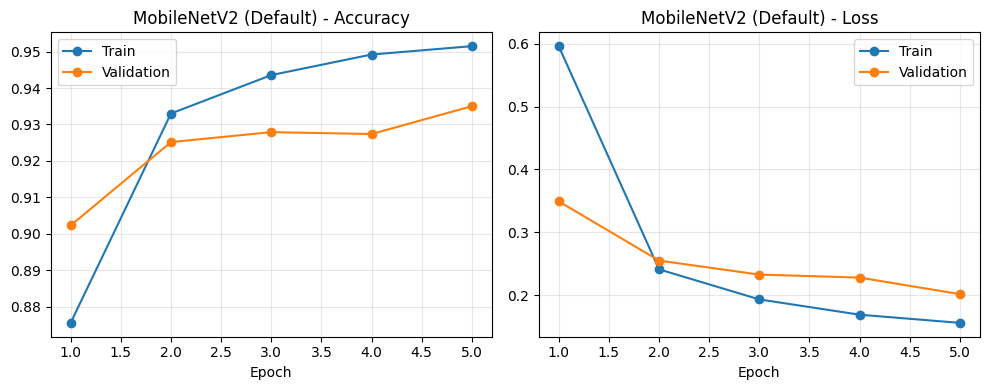

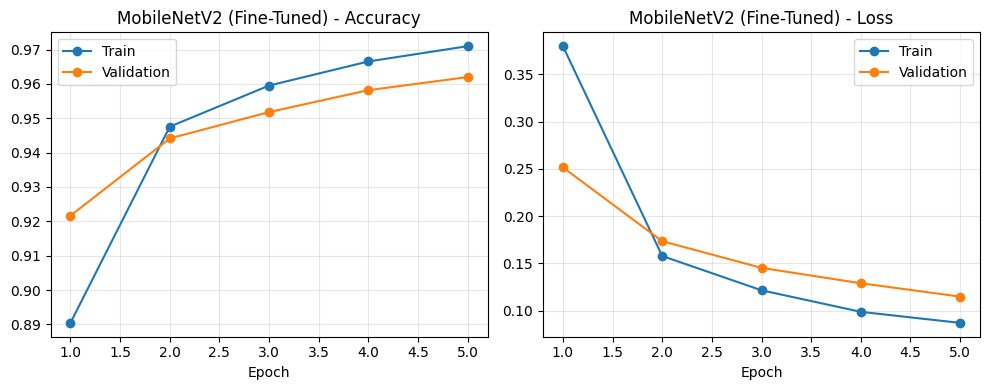

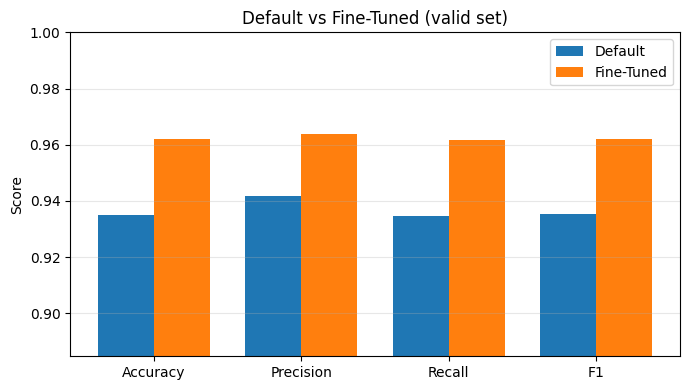

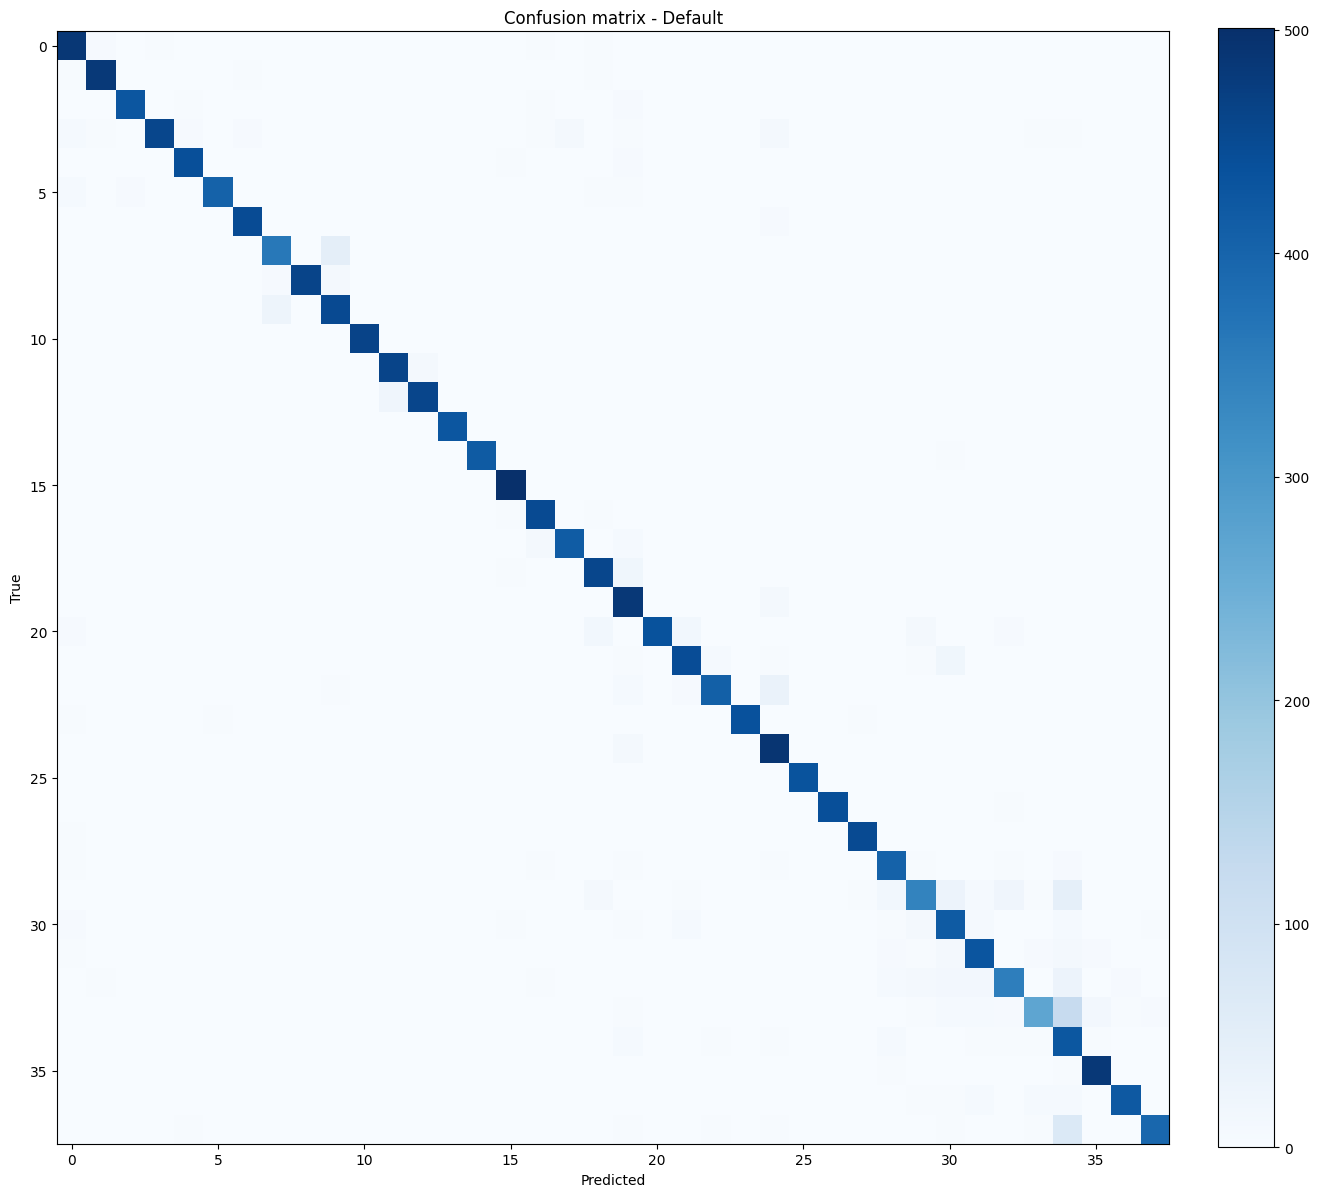

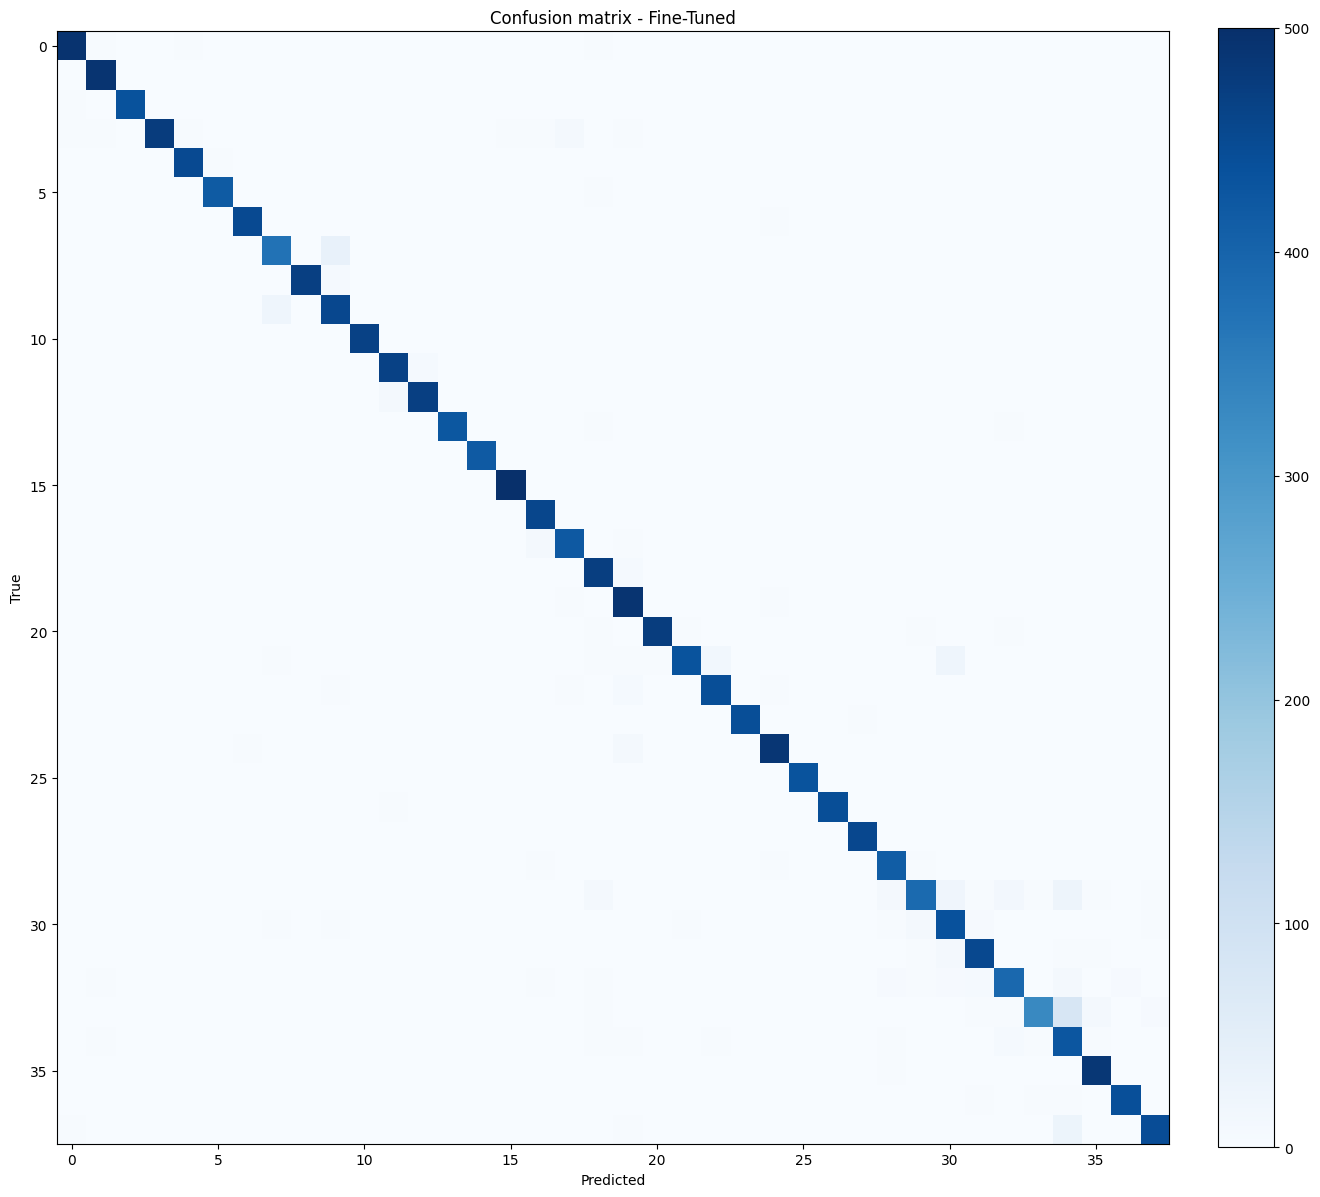

In [12]:
def save_fig(name):
    path = os.path.join(RESULTS_DIR, name)
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    return path

# --- Training curves, one figure per model ---
for hist, title, fname in [
    (history_default,   "MobileNetV2 (Default)",    "curves_default.png"),
    (history_finetuned, "MobileNetV2 (Fine-Tuned)", "curves_finetuned.png"),
]:
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].plot(ep, hist["train_acc"], marker="o", label="Train")
    ax[0].plot(ep, hist["val_acc"],   marker="o", label="Validation")
    ax[0].set_title(f"{title} - Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(ep, hist["train_loss"], marker="o", label="Train")
    ax[1].plot(ep, hist["val_loss"],   marker="o", label="Validation")
    ax[1].set_title(f"{title} - Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); save_fig(fname)

# --- Metric comparison bar chart ---
metrics = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
labels  = ["Accuracy", "Precision", "Recall", "F1"]
x = np.arange(len(metrics)); w = 0.38
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x - w/2, [results_default[m]   for m in metrics], w, label="Default")
ax.bar(x + w/2, [results_finetuned[m] for m in metrics], w, label="Fine-Tuned")
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylabel("Score")
lo = min(min(results_default[m] for m in metrics),
         min(results_finetuned[m] for m in metrics))
ax.set_ylim(max(0, lo - 0.05), 1.0)
ax.set_title(f"Default vs Fine-Tuned ({FINAL_EVAL_NAME} set)"); ax.legend(); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); save_fig("metric_comparison.png")

# --- Confusion matrices ---
def plot_cm(cm, title, fname):
    cm = np.array(cm)
    n = len(class_names)
    size = max(6, min(20, n * 0.35))
    fig, ax = plt.subplots(figsize=(size, size))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(title); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    if n <= 20:
        ax.set_xticks(range(n)); ax.set_yticks(range(n))
        ax.set_xticklabels(class_names, rotation=90, fontsize=7)
        ax.set_yticklabels(class_names, fontsize=7)
        for i in range(n):
            for j in range(n):
                if cm[i, j]:
                    ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6,
                            color="white" if cm[i, j] > cm.max()/2 else "black")
    plt.colorbar(im, fraction=0.046, pad=0.04)
    plt.tight_layout(); save_fig(fname)

plot_cm(results_default["confusion_matrix"],   "Confusion matrix - Default",    "cm_default.png")
plot_cm(results_finetuned["confusion_matrix"], "Confusion matrix - Fine-Tuned", "cm_finetuned.png")

## 9. Save all results (send the `results/` folder to generate the IEEE report)

In [13]:
import platform

all_results = {
    "config": {
        "image_size": IMAGE_SIZE, "batch_size": BATCH_SIZE, "seed": SEED,
        "default_epochs": DEFAULT_EPOCHS, "default_lr": DEFAULT_LR,
        "fine_tune_epochs": FINE_TUNE_EPOCHS, "fine_tune_lr": FINE_TUNE_LR,
        "unfrozen_last_blocks": UNFREEZE_LAST_N_BLOCKS,
        "optimizer": "AdamW", "weight_decay": WEIGHT_DECAY,
        "scheduler": "ReduceLROnPlateau(factor=0.3, patience=2)",
        "early_stop_patience": EARLY_STOP_PAT,
        "loss": "CrossEntropyLoss",
        "augmentation": "RandomResizedCrop(0.8-1.0), HorizontalFlip, Rotation(15), ColorJitter(0.15)",
        "device": str(DEVICE),
        "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
        "torch_version": torch.__version__,
        "python_version": platform.python_version(),
    },
    "dataset": dataset_summary,
    "class_names": class_names,
    "default":    {"history": history_default,   "results": results_default},
    "fine_tuned": {"history": history_finetuned, "results": results_finetuned},
}

with open(os.path.join(RESULTS_DIR, "results.json"), "w", encoding="utf-8") as f:
    json.dump(all_results, f, indent=2, ensure_ascii=False)

print("Saved to:", RESULTS_DIR)
for fn in sorted(os.listdir(RESULTS_DIR)):
    print("  ", fn)
print("\nModel files:")
print("  ", DEFAULT_MODEL_PATH)
print("  ", FINETUNED_MODEL_PATH)
print("  ", LABELS_PATH)

Saved to: /content/saved_model/results
   cm_default.png
   cm_finetuned.png
   curves_default.png
   curves_finetuned.png
   metric_comparison.png
   results.json

Model files:
   /content/saved_model/plant_disease_mobilenetv2_default.pth
   /content/saved_model/plant_disease_mobilenetv2_finetuned.pth
   /content/saved_model/class_labels.json


## 10. Using the saved model for a single image

In [14]:
from PIL import Image

def load_for_inference(model_path):
    ck = torch.load(model_path, map_location=DEVICE)
    m = models.mobilenet_v2(weights=None)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, ck["num_classes"])
    m.load_state_dict(ck["model_state_dict"])
    return m.to(DEVICE).eval(), ck["class_names"]

def predict_image(image_path, model_path=FINETUNED_MODEL_PATH, top_k=3):
    m, names = load_for_inference(model_path)
    x = eval_transform(Image.open(image_path).convert("RGB")).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        probs = torch.softmax(m(x), dim=1)[0]
    conf, idx = probs.topk(top_k)
    return [(names[i], float(c)) for c, i in zip(conf, idx)]

# Example:
# print(predict_image(r"D:\PlantDiseaseDataset\valid\SomeClass\img.jpg"))

In [15]:
import shutil
from google.colab import files

# Define the directory to zip and the output path
folder_to_zip = "/content/saved_model"
output_zip_file = "/content/saved_model_results"

print(f"Creating zip archive of: {folder_to_zip}...")
# Create a zip archive of the directory
shutil.make_archive(output_zip_file, 'zip', folder_to_zip)

# Trigger the download of the zipped file in Colab
zip_path = f"{output_zip_file}.zip"
print(f"Downloading {zip_path} to your local device...")
files.download(zip_path)

Creating zip archive of: /content/saved_model...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>